# Pharmaceutical Demand Forecasting: Teva Pharmaceutical Sales

A ready-to-run, reproducible prototype for diploma research. The notebook:

- loads the **real** `teva_sales_small.csv` file from the public Teva/Marchev Science repository;
- validates the schema and reshapes the 60 monthly columns (2019-01 — 2023-12) into long format;
- runs EDA by SKU, INN, ATC, missing values, zero sales and seasonality;
- carefully extracts strength and pack size from `Description` and assesses pack comparability;
- compares Seasonal Naive, ETS and a global CatBoost model;
- uses a time-based split: **2019–2021 → training, 2022 → validation, 2023 → test**;
- runs a mock cold-start: a subset of SKUs is fully excluded from training, and the features do not use their sales.

> **Important.** The data contain sales in packs, not true patient demand. Zero sales may mean either no demand or no stock. Therefore the conclusions cannot be transferred directly to inventory planning without stock and stockout data.

## 0. Settings and dependencies

In Google Colab, simply choose **Runtime → Run all**. CatBoost and statsmodels are installed only if they are missing. By default, the reduced 20-INN dataset is used — it is large enough for a complete prototype, but noticeably faster than the full file.

In [1]:
import importlib.util, os, re, sys, subprocess, warnings
from pathlib import Path

needed = []
for package, module in [("statsmodels==0.14.5", "statsmodels"), ("catboost==1.2.8", "catboost")]:
    if importlib.util.find_spec(module) is None:
        needed.append(package)
if needed:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *needed])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Can be switched to "full", but the ETS step will take longer.
DATASET = "small"  # "small" or "full"
BASE_URL = "https://raw.githubusercontent.com/Marchev-Science/case-forecasting-pharmacutical-demand/main/data"
DATA_URL = f"{BASE_URL}/teva_sales{'_small' if DATASET == 'small' else ''}.csv"
print("Source:", DATA_URL)

Source: https://raw.githubusercontent.com/Marchev-Science/case-forecasting-pharmacutical-demand/main/data/teva_sales_small.csv


## 1. Loading from GitHub and validating the actual schema

For a local run you can set the `TEVA_DATA_PATH` environment variable. It is not needed in Colab: the raw GitHub file is used. If GitHub is temporarily unavailable, the cell offers to upload the CSV manually.

The validation does not rely on column order: month columns are found with the regular expression `YYYY MM`, after which the date bounds, uniqueness and required fields are checked.

In [2]:
local_override = os.environ.get("TEVA_DATA_PATH")
try:
    raw = pd.read_csv(local_override or DATA_URL)
except Exception as exc:
    print("Automatic download failed:", exc)
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("No file selected")
        raw = pd.read_csv(next(iter(uploaded)))
    except ImportError:
        raise RuntimeError("Set TEVA_DATA_PATH or run the notebook in Colab") from exc

required = ["Morion ID", "INN", "Description", "NFC (1)"] + [f"ATC Code ({i})" for i in range(1, 6)]
missing_required = [c for c in required if c not in raw.columns]
assert not missing_required, f"Missing required fields: {missing_required}"

month_cols = sorted([c for c in raw.columns if re.fullmatch(r"\d{4} \d{2}", str(c))])
assert len(month_cols) == 60, f"Expected 60 monthly columns, found {len(month_cols)}"
month_dates = pd.to_datetime(month_cols, format="%Y %m")
assert month_dates[0] == pd.Timestamp("2019-01-01") and month_dates[-1] == pd.Timestamp("2023-12-01")
assert raw["Morion ID"].is_unique, "Morion ID must uniquely identify an SKU"

raw[month_cols] = raw[month_cols].apply(pd.to_numeric, errors="coerce")
schema_summary = pd.DataFrame({
    "metric": ["rows / SKUs", "columns", "monthly columns", "start", "end"],
    "value": [len(raw), raw.shape[1], len(month_cols), month_cols[0], month_cols[-1]],
})
display(schema_summary)
display(raw.head(3))

,metric,value
0,rows / SKUs,1730
1,columns,70
2,monthly columns,60
3,start,2019 01
4,end,2023 12


,Morion ID,ATC Code (1),ATC Code (2),ATC Code (3),ATC Code (4),ATC Code (5),Brand,INN,NFC (1),Description,2019 01,2019 02,2019 03,2019 04,2019 05,2019 06,2019 07,2019 08,2019 09,2019 10,2019 11,2019 12,2020 01,2020 02,2020 03,2020 04,2020 05,2020 06,2020 07,2020 08,2020 09,2020 10,2020 11,2020 12,2021 01,2021 02,2021 03,2021 04,2021 05,2021 06,2021 07,2021 08,2021 09,2021 10,2021 11,2021 12,2022 01,2022 02,2022 03,2022 04,2022 05,2022 06,2022 07,2022 08,2022 09,2022 10,2022 11,2022 12,2023 01,2023 02,2023 03,2023 04,2023 05,2023 06,2023 07,2023 08,2023 09,2023 10,2023 11,2023 12
0,386946,N NERVOUS SYSTEM,N06 PSYCHOANALEPTICS,"N06B PSYCHOSTIMULANTS, AGENTS USED FOR ADHD AN...",N06B X Other psychostimulants and nootropics,N06B X06 Citicoline,38213,CITICOLINUM,Parenteral Ordinary,"sol. for inj. 500 mg amp. 2 ml, contour cell...",0.16,0.00,1.70,1.12,0.67,0.21,10.96,2.48,0.00,0.00,0.00,0.00,0.00,11.21,0.00,0.00,0.00,0.00,0.00,5.58,0.00,6.16,0.00,0.00,0.52,0.00,0.00,4.67,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.32,2.34,1.54,2.64,2.34,1.43,2.34,1.87,1.94,1.61,0.50,0.00,0.00,0.00,1.52,0.25,0.63,0.00,0.00,2.32,2.78,2.18,2.20,0.90,0.00
1,74519,C CARDIOVASCULAR SYSTEM,C10 LIPID MODIFYING AGENTS,"C10A LIPID MODIFYING AGENTS, PLAIN",C10A A HMG CoA reductase inhibitors,C10A A05 Atorvastatin,34727,ATORVASTATINUM,Oral Solid Ordinary,"tabs coated w/film 20 mg blister, #30",0.21,2.12,2.84,1.41,2.24,10.74,16.43,11.94,26.07,19.03,52.98,38.96,0.00,2.92,6.03,0.45,1.54,5.98,11.52,11.83,23.74,17.25,20.92,34.30,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.78,48.74,254.32,346.21,342.18,272.44,325.14,356.34,341.45,346.76,403.78,262.30,244.03,169.18,118.12,66.78,44.94,9.12,0.00,1.50
2,410903,M MUSCULO-SCELETAL SYSTEM,M01 ANTIINFLAMMATORY AND ANTIRHEUMATIC PRODUCTS,M01A ANTIINFLAMMATORY AND ANTIRHEUMATIC PRODUC...,M01A B Acetic acid derivatives and related sub...,M01A B05 Diclofenac,3419,DICLOFENACUM,Parenteral Ordinary,"sol. for inj. 25 mg/ml amp. 3 ml, #5",0.34,199.41,1060.58,1270.29,1552.52,1822.96,2283.38,2353.38,2261.63,2676.72,3107.12,2944.21,3246.94,3253.05,2610.05,1515.98,2069.43,1904.76,2358.98,2602.22,2497.03,2690.16,2846.54,2601.36,2387.00,2624.72,2574.61,2422.18,2798.96,2783.27,2769.14,2940.16,2626.43,2554.74,2547.36,2456.47,2617.96,2755.12,3186.94,1589.10,1891.38,1756.07,1978.24,1947.14,2087.72,2287.98,2535.54,2277.47,2477.38,2394.98,3021.94,2816.27,3220.27,2949.32,2948.98,2805.72,2415.24,1510.04,954.41,656.89


## 2. Reshaping into an SKU × month panel

Each row of `long` holds the sales of one SKU in one month. Missing values are **not replaced with zeros**: these are different states. Negative values are also checked separately.

In [3]:
id_cols = [c for c in raw.columns if c not in month_cols]
long = raw.melt(id_vars=id_cols, value_vars=month_cols,
                var_name="month_raw", value_name="sales")
long["date"] = pd.to_datetime(long["month_raw"], format="%Y %m")
long = long.sort_values(["Morion ID", "date"]).reset_index(drop=True)
long["year"] = long["date"].dt.year
long["month"] = long["date"].dt.month

assert len(long) == len(raw) * 60
assert not long.duplicated(["Morion ID", "date"]).any()

quality = pd.DataFrame({
    "metric": ["SKUs", "INNs", "observations", "missing sales", "zero sales", "negative sales"],
    "value": [raw["Morion ID"].nunique(), raw["INN"].nunique(), len(long),
              long["sales"].isna().sum(), long["sales"].eq(0).sum(), long["sales"].lt(0).sum()],
})
quality["share"] = [np.nan, np.nan, np.nan,
                    long["sales"].isna().mean(), long["sales"].eq(0).mean(), long["sales"].lt(0).mean()]
display(quality)

,metric,value,share
0,SKUs,1730,NaN
1,INNs,20,NaN
2,observations,103800,NaN
3,missing sales,0,0.000000
4,zero sales,33262,0.320443
5,negative sales,0,0.000000


## 3. EDA: SKUs, INNs, ATC, missing values and zeros

WAPE below is computed as the sum of absolute errors divided by the sum of actual sales. Unlike MAPE, it handles individual zero observations correctly (but not an entirely zero sample).

,entity,unique,missing
0,SKU,1730,0
1,INN,20,0
2,brands,405,0
3,NFC forms,9,0
4,ATC Code (1),10,0
5,ATC Code (2),17,0
6,ATC Code (3),20,0
7,ATC Code (4),25,0
8,ATC Code (5),29,0


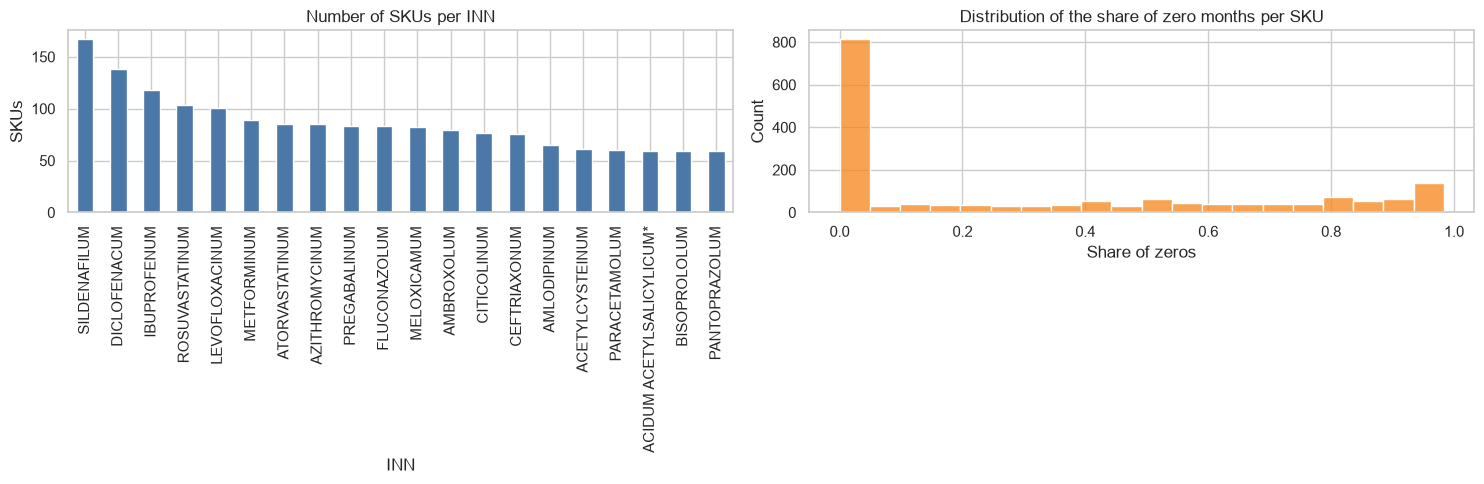

,SKU,INN
ATC Code (1),,
J GENERAL ANTIINFECTIVES FOR SYSTEMIC USE,334,4
M MUSCULO-SCELETAL SYSTEM,330,3
C CARDIOVASCULAR SYSTEM,313,4
N NERVOUS SYSTEM,235,4
G GENITO URINARY SYSTEM AND SEX HORMONES,167,1
A ALIMENTARY TRACT AND METABOLISM,148,2
R RESPIRATORY SYSTEM,140,2
B BLOOD AND BLOOD FORMING ORGANS,44,1
S SENSORY ORGANS,16,3


In [4]:
atc_cols = [f"ATC Code ({i})" for i in range(1, 6)]
overview = pd.DataFrame({
    "entity": ["SKU", "INN", "brands", "NFC forms"] + atc_cols,
    "unique": [raw["Morion ID"].nunique(), raw["INN"].nunique(), raw["Brand"].nunique(),
               raw["NFC (1)"].nunique()] + [raw[c].nunique(dropna=True) for c in atc_cols],
    "missing": [raw["Morion ID"].isna().sum(), raw["INN"].isna().sum(), raw["Brand"].isna().sum(),
                raw["NFC (1)"].isna().sum()] + [raw[c].isna().sum() for c in atc_cols]
})
display(overview)

sku_per_inn = raw.groupby("INN")["Morion ID"].nunique().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sku_per_inn.plot.bar(ax=axes[0], color="#4C78A8", title="Number of SKUs per INN")
axes[0].set_ylabel("SKUs")
zero_by_sku = long.groupby("Morion ID")["sales"].apply(lambda s: s.eq(0).mean())
sns.histplot(zero_by_sku, bins=20, ax=axes[1], color="#F58518")
axes[1].set(title="Distribution of the share of zero months per SKU", xlabel="Share of zeros")
plt.tight_layout(); plt.show()

atc1 = raw.groupby("ATC Code (1)").agg(SKU=("Morion ID", "nunique"), INN=("INN", "nunique"))
display(atc1.sort_values("SKU", ascending=False))

In [5]:
sku_stats = long.groupby(["Morion ID", "INN"], as_index=False).agg(
    total_sales=("sales", "sum"),
    mean_sales=("sales", "mean"),
    zero_share=("sales", lambda s: s.eq(0).mean()),
    first_positive=("date", lambda s: s[long.loc[s.index, "sales"].gt(0)].min() if long.loc[s.index, "sales"].gt(0).any() else pd.NaT),
    positive_months=("sales", lambda s: s.gt(0).sum()),
)
sku_stats["new_after_2021"] = sku_stats["first_positive"] >= "2022-01-01"
display(sku_stats.sort_values("total_sales", ascending=False).head(10))
print(f"SKUs with no sales in all 60 months: {(sku_stats.positive_months == 0).sum()}")
print(f"SKUs first sold in 2022 or later: {sku_stats.new_after_2021.sum()}")

,Morion ID,INN,total_sales,mean_sales,zero_share,first_positive,positive_months,new_after_2021
819,194013,PARACETAMOLUM,41084222.34,684737.039000,0.0,2019-01-01,60,False
49,5558,ACIDUM ACETYLSALICYLICUM*,39863489.56,664391.492667,0.0,2019-01-01,60,False
71,13405,CEFTRIAXONUM,22173618.61,369560.310167,0.0,2019-01-01,60,False
490,114619,ACIDUM ACETYLSALICYLICUM*,21154009.28,352566.821333,0.0,2019-01-01,60,False
657,153062,PARACETAMOLUM,14912916.98,248548.616333,0.0,2019-01-01,60,False
683,155363,ACIDUM ACETYLSALICYLICUM*,10513088.89,175218.148167,0.0,2019-01-01,60,False
484,112504,BISOPROLOLUM,9304346.80,155072.446667,0.0,2019-01-01,60,False
257,69828,ACIDUM ACETYLSALICYLICUM*,9110661.02,151844.350333,0.0,2019-01-01,60,False
1317,448549,METFORMINUM,8222057.36,137034.289333,0.0,2019-01-01,60,False
194,55932,CEFTRIAXONUM,8041291.60,134021.526667,0.0,2019-01-01,60,False


SKUs with no sales in all 60 months: 0
SKUs first sold in 2022 or later: 179


## 4. Seasonality

To avoid confusing seasonality with scale, sales are first summed by INN, and then each INN's monthly values are divided by its mean. A seasonal index of 1.20 means that this calendar month is, on average, 20% above the mean level of that INN.

The lag-12 correlation is a diagnostic indicator, not proof of stable seasonality: only five years of data are available.

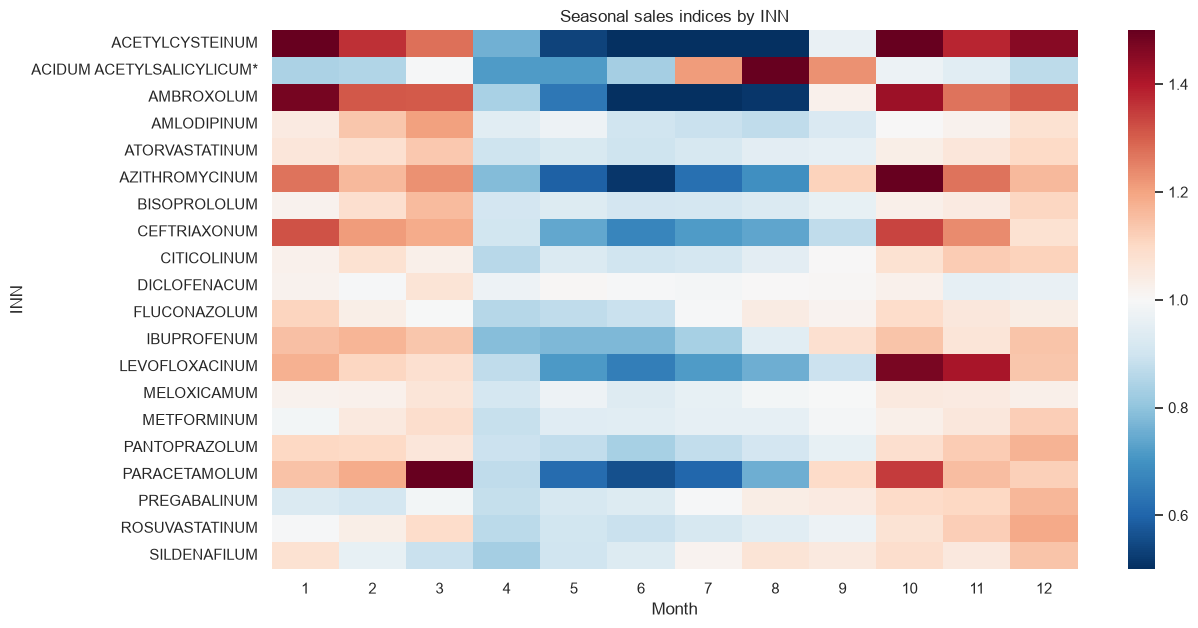

,corr_lag12
INN,
PREGABALINUM,0.876144
AMLODIPINUM,0.652860
ACIDUM ACETYLSALICYLICUM*,0.645426
ROSUVASTATINUM,0.564539
DICLOFENACUM,0.551793
ACETYLCYSTEINUM,0.547873
AMBROXOLUM,0.541705
CEFTRIAXONUM,0.509760
LEVOFLOXACINUM,0.357391


In [6]:
inn_month = long.groupby(["INN", "date"], as_index=False)["sales"].sum(min_count=1)
inn_month["month"] = inn_month["date"].dt.month
inn_month["season_index"] = inn_month["sales"] / inn_month.groupby("INN")["sales"].transform("mean")
season_table = inn_month.pivot_table(index="INN", columns="month", values="season_index", aggfunc="mean")

plt.figure(figsize=(13, 7))
sns.heatmap(season_table, cmap="RdBu_r", center=1, vmin=0.5, vmax=1.5)
plt.title("Seasonal sales indices by INN")
plt.xlabel("Month"); plt.ylabel("INN"); plt.show()

lag12_corr = inn_month.groupby("INN")["sales"].apply(lambda s: s.corr(s.shift(12))).sort_values(ascending=False)
display(lag12_corr.rename("corr_lag12").to_frame())

## 5. Strengths, pack sizes and their comparability

`Description` is unstructured text. The regular expressions below extract only the first strength-like fragment and the last token of the form `#30`. This is a **heuristic**, not a pharmaceutical parser.

Strengths are converted to mg only for `mcg/µg`, `mg` and `g`. Percentages, IU, concentrations and combination products cannot be compared with this simple rule. Packs are considered comparable only within the same INN, NFC form, strength and pack size.

In [7]:
def parse_strength(text):
    text = str(text).lower().replace(",", ".")
    m = re.search(r"(?<![#\d])(\d+(?:\.\d+)?)\s*(mcg|µg|ug|mg|g)\b", text)
    if not m:
        return pd.Series([np.nan, None])
    value, unit = float(m.group(1)), m.group(2)
    factor = {"mcg": 0.001, "µg": 0.001, "ug": 0.001, "mg": 1.0, "g": 1000.0}[unit]
    return pd.Series([value * factor, unit])

def parse_pack(text):
    hits = re.findall(r"#\s*(\d+)", str(text))
    return float(hits[-1]) if hits else np.nan

parsed = raw["Description"].apply(parse_strength)
raw[["strength_mg", "strength_unit_raw"]] = parsed
raw["pack_count"] = raw["Description"].apply(parse_pack)
raw["presentation_parsed"] = raw["strength_mg"].notna() & raw["pack_count"].notna()

keys = ["INN", "NFC (1)", "strength_mg", "pack_count"]
raw["comparable_group_size"] = raw.groupby(keys, dropna=False)["Morion ID"].transform("size")
raw["strictly_comparable"] = raw["presentation_parsed"] & raw["comparable_group_size"].ge(2)

parse_report = pd.DataFrame({
    "metric": ["strength recognized", "pack size recognized", "both fields recognized", "has a comparable SKU"],
    "SKU count": [raw.strength_mg.notna().sum(), raw.pack_count.notna().sum(),
                  raw.presentation_parsed.sum(), raw.strictly_comparable.sum()],
})
parse_report["share"] = parse_report["SKU count"] / len(raw)
display(parse_report)
display(raw.loc[raw.strictly_comparable, ["Morion ID", "INN", "NFC (1)", "Description", "strength_mg", "pack_count"]].head(10))

,metric,SKU count,share
0,strength recognized,1706,0.986127
1,pack size recognized,1683,0.972832
2,both fields recognized,1661,0.960116
3,has a comparable SKU,1497,0.865318


,Morion ID,INN,NFC (1),Description,strength_mg,pack_count
0,386946,CITICOLINUM,Parenteral Ordinary,"sol. for inj. 500 mg amp. 2 ml, contour cell...",500.0,10.0
1,74519,ATORVASTATINUM,Oral Solid Ordinary,"tabs coated w/film 20 mg blister, #30",20.0,30.0
2,410903,DICLOFENACUM,Parenteral Ordinary,"sol. for inj. 25 mg/ml amp. 3 ml, #5",25.0,5.0
4,198282,AMLODIPINUM,Oral Solid Ordinary,"tabs 5 mg blister, #60",5.0,60.0
5,485156,CITICOLINUM,Parenteral Ordinary,"sol. for inj. 500 mg/4 ml amp. 4 ml, blister...",500.0,5.0
6,85813,AZITHROMYCINUM,Oral Solid Ordinary,"tablets coated 250 mg, #6",250.0,6.0
7,171324,ATORVASTATINUM,Oral Solid Ordinary,"tabs coated w/film 20 mg blister, #30",20.0,30.0
8,327027,METFORMINUM,Oral Solid Ordinary,"tabs coated w/film 850 mg blister, in box, #30",850.0,30.0
10,190958,IBUPROFENUM,Oral Liquid Ordinary,"oral suspens. 100 mg/5 ml flask 200 ml, with ...",100.0,1.0
11,51878,SILDENAFILUM,Oral Solid Ordinary,"tabs coated w/film 50 mg blister, #4",50.0,4.0


## 6. Evaluation protocol and metrics

- **Validation:** the model is trained on data up to 2021-12 and forecasts 2022.
- **Final test:** after the approach is chosen, the model is retrained on data up to 2022-12 and forecasts 2023.
- **MAE:** mean absolute error in sales units.
- **WAPE:** total absolute error / total actual sales. The main aggregate metric.

Seasonal Naive uses the value from exactly 12 months earlier. This is a fair baseline for a 12-month horizon: all required values are known at the forecast origin.

In [8]:
# Merge the parsed attributes back into long.
attrs = raw[["Morion ID", "strength_mg", "pack_count", "presentation_parsed"]]
long = long.drop(columns=[c for c in attrs.columns[1:] if c in long.columns], errors="ignore").merge(attrs, on="Morion ID", how="left")
long["lag12"] = long.groupby("Morion ID")["sales"].shift(12)
long["lag24"] = long.groupby("Morion ID")["sales"].shift(24)
long["month_sin"] = np.sin(2 * np.pi * long["month"] / 12)
long["month_cos"] = np.cos(2 * np.pi * long["month"] / 12)

def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

def wape(y, p):
    den = np.sum(np.abs(np.asarray(y)))
    return float(np.sum(np.abs(np.asarray(y) - np.asarray(p))) / den) if den > 0 else np.nan

def score_frame(df, actual="sales", pred="prediction"):
    z = df[[actual, pred]].dropna()
    return {"n": len(z), "MAE": mae(z[actual], z[pred]), "WAPE": wape(z[actual], z[pred])}

def seasonal_naive_for(year):
    z = long.loc[long.year.eq(year), ["Morion ID", "INN", "date", "sales", "lag12"]].copy()
    z["prediction"] = z["lag12"].clip(lower=0)
    z["model"] = "Seasonal Naive"
    return z

val_naive = seasonal_naive_for(2022)
test_naive = seasonal_naive_for(2023)
display(pd.DataFrame([score_frame(val_naive), score_frame(test_naive)], index=["Validation 2022", "Test 2023"]))

,n,MAE,WAPE
Validation 2022,20760,3548.269403,0.594755
Test 2023,20760,2485.556304,0.422200


## 7. ETS: a separate model for each SKU

Holt–Winters with additive trend and seasonality (12 months) is used. For all-zero, too short or unstable series there is a fair fallback — the mean of the last 12 available months. Negative forecasts are clipped to zero.

ETS is fitted separately for each SKU, so it **does not solve cold-start**. It serves as a classical statistical baseline.

In [9]:
def ets_forecast(train_values, horizon=12):
    y = pd.Series(train_values, dtype=float).dropna().to_numpy()
    fallback = np.repeat(np.mean(y[-12:]) if len(y) else 0.0, horizon)
    if len(y) < 24 or np.allclose(y, y[0]):
        return np.clip(fallback, 0, None), "fallback"
    try:
        fit = ExponentialSmoothing(
            y, trend="add", seasonal="add", seasonal_periods=12,
            initialization_method="estimated"
        ).fit(optimized=True, use_brute=False)
        return np.clip(fit.forecast(horizon), 0, None), "ets"
    except Exception:
        return np.clip(fallback, 0, None), "fallback"

def run_ets(cutoff, forecast_year):
    rows, modes = [], []
    forecast_dates = pd.date_range(f"{forecast_year}-01-01", periods=12, freq="MS")
    for sku, g in long[long.date <= pd.Timestamp(cutoff)].groupby("Morion ID", sort=False):
        pred, mode = ets_forecast(g.sort_values("date").sales, 12)
        modes.append(mode)
        rows.extend(zip([sku] * 12, forecast_dates, pred))
    out = pd.DataFrame(rows, columns=["Morion ID", "date", "prediction"])
    actual = long.loc[long.year.eq(forecast_year), ["Morion ID", "INN", "date", "sales"]]
    out = actual.merge(out, on=["Morion ID", "date"], how="left")
    out["model"] = "ETS"
    print(f"{forecast_year}: ETS={modes.count('ets')}, fallback={modes.count('fallback')}")
    return out

val_ets = run_ets("2021-12-01", 2022)
test_ets = run_ets("2022-12-01", 2023)
display(pd.DataFrame([score_frame(val_ets), score_frame(test_ets)], index=["Validation 2022", "Test 2023"]))

2022: ETS=1551, fallback=179


2023: ETS=1648, fallback=82


,n,MAE,WAPE
Validation 2022,20760,3645.977804,0.611133
Test 2023,20760,2354.791290,0.399988


## 8. Global CatBoost without temporal leakage

CatBoost is a reasonable choice here because there are thousands of SKUs, categorical relationships between SKU/INN/ATC/form, and non-linear interactions. A single model is shared by all SKUs.

Only the following features are allowed:

- static product attributes;
- calendar month;
- `lag12` and `lag24`.

Lags 1–11 and rolling means are intentionally not used: when all 12 months are forecast at once, they would require unknown actual sales from inside the horizon. Missing categorical values are encoded as the string `MISSING`; CatBoost handles missing numeric values natively.

In [10]:
cat_features = ["Morion ID", "INN", "ATC Code (1)", "ATC Code (2)", "ATC Code (3)", "ATC Code (4)", "ATC Code (5)", "NFC (1)"]
num_features = ["month", "month_sin", "month_cos", "lag12", "lag24", "strength_mg", "pack_count"]
features = cat_features + num_features

def prepare_X(df, cats=cat_features, nums=num_features):
    X = df[cats + nums].copy()
    for c in cats:
        X[c] = X[c].fillna("MISSING").astype(str)
    for c in nums:
        X[c] = pd.to_numeric(X[c], errors="coerce")
    return X

def fit_catboost(train_end, predict_year):
    train = long[(long.date <= pd.Timestamp(train_end)) & long.lag12.notna() & long.sales.notna()].copy()
    target = long[(long.year == predict_year) & long.sales.notna()].copy()
    model = CatBoostRegressor(
        iterations=350, depth=7, learning_rate=0.06, loss_function="MAE",
        random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False,
        thread_count=-1
    )
    model.fit(prepare_X(train), train.sales, cat_features=cat_features)
    out = target[["Morion ID", "INN", "date", "sales"]].copy()
    out["prediction"] = np.clip(model.predict(prepare_X(target)), 0, None)
    out["model"] = "CatBoost"
    return model, out

cat_val_model, val_cat = fit_catboost("2021-12-01", 2022)
cat_test_model, test_cat = fit_catboost("2022-12-01", 2023)
display(pd.DataFrame([score_frame(val_cat), score_frame(test_cat)], index=["Validation 2022", "Test 2023"]))

,n,MAE,WAPE
Validation 2022,20760,3584.023792,0.600748
Test 2023,20760,2575.333250,0.437449


## 9. Comparison on validation and final test

The method should be selected based on 2022. The 2023 result is shown as the single final evaluation and must not be used for further tuning.

,n,MAE,WAPE,split,model
4,20760,2354.791290,0.399988,Test 2023,ETS
3,20760,2485.556304,0.422200,Test 2023,Seasonal Naive
5,20760,2575.333250,0.437449,Test 2023,CatBoost
0,20760,3548.269403,0.594755,Validation 2022,Seasonal Naive
2,20760,3584.023792,0.600748,Validation 2022,CatBoost
1,20760,3645.977804,0.611133,Validation 2022,ETS


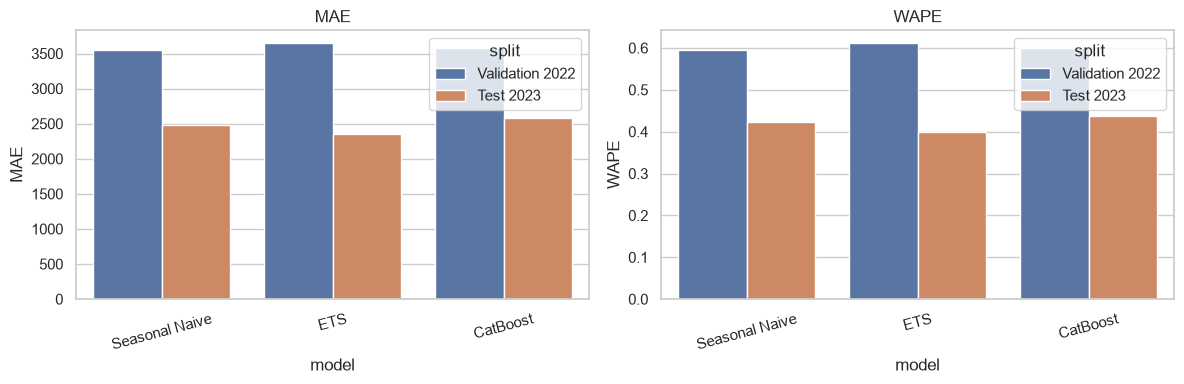

In [11]:
def comparison(frames, split):
    rows = []
    for f in frames:
        s = score_frame(f)
        s.update({"split": split, "model": f["model"].iloc[0]})
        rows.append(s)
    return pd.DataFrame(rows)

metrics = pd.concat([
    comparison([val_naive, val_ets, val_cat], "Validation 2022"),
    comparison([test_naive, test_ets, test_cat], "Test 2023"),
], ignore_index=True)
display(metrics.sort_values(["split", "WAPE"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=metrics, x="model", y="MAE", hue="split", ax=axes[0])
sns.barplot(data=metrics, x="model", y="WAPE", hue="split", ax=axes[1])
axes[0].set_title("MAE"); axes[1].set_title("WAPE")
for ax in axes: ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

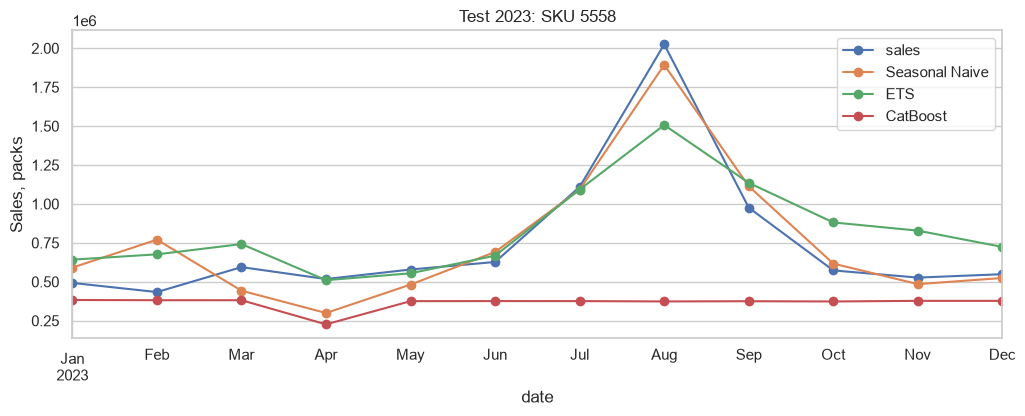

In [12]:
# Actuals and forecasts for the SKU with the highest sales in 2023.
top_sku = test_cat.groupby("Morion ID").sales.sum().idxmax()
plot_df = (test_naive[test_naive["Morion ID"] == top_sku][["date", "sales", "prediction"]]
           .rename(columns={"prediction": "Seasonal Naive"}))
plot_df = plot_df.merge(test_ets[test_ets["Morion ID"] == top_sku][["date", "prediction"]]
                        .rename(columns={"prediction": "ETS"}), on="date")
plot_df = plot_df.merge(test_cat[test_cat["Morion ID"] == top_sku][["date", "prediction"]]
                        .rename(columns={"prediction": "CatBoost"}), on="date")
plot_df.set_index("date").plot(figsize=(12, 4), marker="o", title=f"Test 2023: SKU {top_sku}")
plt.ylabel("Sales, packs"); plt.show()

## 10. Mock cold-start: holding out entire SKUs

This tests the ability to transfer knowledge between products, not a regular time-series forecast.

1. In each INN with at least 5 SKUs, 20% of the SKUs are held out at random (with a fixed seed).
2. All rows of these SKUs are completely removed from training.
3. The SKU identifier and the SKU's own lags are not used.
4. For held-out SKUs, only the static product card and the total sales of **other SKUs of the same INN 12 months earlier** are allowed.
5. The year 2023 is forecast; training rows end at 2022-12.

Thus, held-out SKU sales enter neither the training target nor the peer-feature aggregate. This is a mock cold-start, because the SKU card and its INN membership are still known.

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
holdout_skus = []
for inn, ids in raw.groupby("INN")["Morion ID"]:
    ids = np.array(sorted(ids.unique()))
    if len(ids) >= 5:
        n_hold = max(1, int(round(0.20 * len(ids))))
        holdout_skus.extend(rng.choice(ids, size=n_hold, replace=False).tolist())
holdout_skus = set(holdout_skus)
train_skus = set(raw["Morion ID"]) - holdout_skus
print(f"Train SKU: {len(train_skus)}, held-out SKU: {len(holdout_skus)}")

# The aggregate is built from train SKUs only and then shifted by 12 months.
pool = (long[long["Morion ID"].isin(train_skus)]
        .groupby(["INN", "date"], as_index=False)["sales"].sum()
        .rename(columns={"sales": "inn_pool_lag12"}))
pool["date"] = pool["date"] + pd.DateOffset(months=12)
cold = long.merge(pool, on=["INN", "date"], how="left")

# For train SKUs, subtract their own lag12 so that the peer feature covers other SKUs only.
is_train_sku = cold["Morion ID"].isin(train_skus)
cold["peer_inn_lag12"] = cold["inn_pool_lag12"]
cold.loc[is_train_sku, "peer_inn_lag12"] = (
    cold.loc[is_train_sku, "inn_pool_lag12"] - cold.loc[is_train_sku, "lag12"].fillna(0)
)

cold_cats = ["INN", "ATC Code (1)", "ATC Code (2)", "ATC Code (3)", "ATC Code (4)", "ATC Code (5)", "NFC (1)"]
cold_nums = ["month", "month_sin", "month_cos", "strength_mg", "pack_count", "peer_inn_lag12"]

cold_train = cold[(cold["Morion ID"].isin(train_skus)) & (cold.date <= "2022-12-01") &
                  cold.sales.notna() & cold.peer_inn_lag12.notna()].copy()
cold_test = cold[(cold["Morion ID"].isin(holdout_skus)) & (cold.year == 2023) & cold.sales.notna()].copy()

cold_model = CatBoostRegressor(
    iterations=400, depth=7, learning_rate=0.06, loss_function="MAE",
    random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False, thread_count=-1
)
cold_model.fit(prepare_X(cold_train, cold_cats, cold_nums), cold_train.sales, cat_features=cold_cats)
cold_test["prediction"] = np.clip(cold_model.predict(prepare_X(cold_test, cold_cats, cold_nums)), 0, None)
cold_test["model"] = "Cold-start CatBoost"

# Baseline without SKU history: the SKU's share within its INN is unknown, so we take the median sales
# of train SKUs of the same INN and calendar month over the history before 2023.
baseline_lookup = (cold_train.groupby(["INN", "month"])["sales"].median().rename("cold_baseline").reset_index())
cold_test = cold_test.merge(baseline_lookup, on=["INN", "month"], how="left")
cold_test["cold_baseline"] = cold_test["cold_baseline"].fillna(cold_train.sales.median()).clip(lower=0)

cold_scores = pd.DataFrame([
    {"model": "INN-month median", **score_frame(cold_test, pred="cold_baseline")},
    {"model": "Cold-start CatBoost", **score_frame(cold_test)},
])
display(cold_scores)

Train SKU: 1383, held-out SKU: 347


,model,n,MAE,WAPE
0,INN-month median,4164,6626.223985,0.989345
1,Cold-start CatBoost,4164,10057.263181,1.501626


In [14]:
# Explicit automated leakage checks for the cold-start setup.
assert set(cold_train["Morion ID"]).isdisjoint(holdout_skus)
assert cold_train.date.max() <= pd.Timestamp("2022-12-01")
assert cold_test.date.min() >= pd.Timestamp("2023-01-01")
assert "Morion ID" not in cold_cats + cold_nums
assert "lag12" not in cold_nums and "lag24" not in cold_nums
assert np.isfinite(cold_test["prediction"]).all()
print("Cold-start checks passed: held-out SKUs are absent from training; the SKU's own history is not used.")

by_inn_cold = cold_test.groupby("INN").apply(
    lambda g: pd.Series({"SKU": g["Morion ID"].nunique(), "MAE": mae(g.sales, g.prediction), "WAPE": wape(g.sales, g.prediction)}),
    include_groups=False
).sort_values("WAPE")
display(by_inn_cold)

Cold-start checks passed: held-out SKUs are absent from training; the SKU's own history is not used.


,SKU,MAE,WAPE
INN,,,
ROSUVASTATINUM,21.0,3725.967344,0.912405
BISOPROLOLUM,12.0,18456.547692,0.935524
METFORMINUM,18.0,16636.209557,0.954811
CITICOLINUM,15.0,3015.050020,0.956510
LEVOFLOXACINUM,20.0,1337.011922,0.965726
PREGABALINUM,17.0,3812.838243,0.974898
FLUCONAZOLUM,17.0,7340.014082,0.996559
ACIDUM ACETYLSALICYLICUM*,12.0,43142.553592,1.000591
ATORVASTATINUM,17.0,1367.913093,1.005905


## 11. Automatic conclusions for the current run

The text below is generated from the metrics actually computed, so the conclusions update automatically when the input file or parameters change.

In [15]:
best_val = metrics.loc[metrics.split.eq("Validation 2022")].sort_values("WAPE").iloc[0]
best_test = metrics.loc[metrics.split.eq("Test 2023")].sort_values("WAPE").iloc[0]
cold_best = cold_scores.sort_values("WAPE").iloc[0]

display(Markdown(f'''
### Key results

- The sample contains **{raw['Morion ID'].nunique():,} SKUs** and **{raw['INN'].nunique()} INNs**; the share of zero SKU-months is **{long.sales.eq(0).mean():.1%}**.
- Strictly comparable analogues (same INN, form, parsed strength and pack size) were found for **{raw.strictly_comparable.mean():.1%} of SKUs**. This is a lower bound: a simple regex does not understand every description format.
- By WAPE on the 2022 validation, the best method is **{best_val['model']}** ({best_val['WAPE']:.1%}). Validation is what should be used to choose the approach.
- On the held-out year 2023, the lowest WAPE was achieved by **{best_test['model']}** ({best_test['WAPE']:.1%}). This is the final evaluation, not another tuning stage.
- In the mock cold-start, the better of the two variants is **{cold_best['model']}**, with a WAPE of **{cold_best['WAPE']:.1%}** on {len(holdout_skus)} fully excluded SKUs.
'''))


### Key results

- The sample contains **1,730 SKUs** and **20 INNs**; the share of zero SKU-months is **32.0%**.
- Strictly comparable analogues (same INN, form, parsed strength and pack size) were found for **86.5% of SKUs**. This is a lower bound: a simple regex does not understand every description format.
- By WAPE on the 2022 validation, the best method is **Seasonal Naive** (59.5%). Validation is what should be used to choose the approach.
- On the held-out year 2023, the lowest WAPE was achieved by **ETS** (40.0%). This is the final evaluation, not another tuning stage.
- In the mock cold-start, the better of the two variants is **INN-month median**, with a WAPE of **98.9%** on 347 fully excluded SKUs.


## 12. Limitations and correct interpretation for the diploma

1. **Sales ≠ true demand.** Without stock levels, stockouts and prices, it is impossible to distinguish an absence of demand from an absence of product.
2. **Only 60 months.** Five annual cycles are too few for confident conclusions about seasonality and structural shifts.
3. **Anonymized and sampled dataset.** Results on 20 INNs do not guarantee transferability to a pharmacy chain, a country or a full portfolio.
4. **Packs are heterogeneous.** The target is packs, not tablets, doses or mg of active substance. The regex parsing requires manual validation on a labeled subsample.
5. **Substitution between SKUs.** Zeros and spikes may result from switching between analogues; an independent ETS model does not capture this.
6. **WAPE is dominated by large SKUs.** For the diploma, it is worth additionally reporting MAE/WAPE by INN, by volume quantiles and by share of zeros.
7. **A mock cold-start is not a new drug launch.** INN, ATC, form and description are known here, and the distribution of held-out SKUs matches the historical portfolio.
8. **No causal interpretation.** CatBoost captures predictive relationships, but it does not prove that strength or form causes changes in sales.

### What to improve in the next iteration

- manually label 100–200 `Description` values and estimate the parser's precision/recall;
- add rolling-origin backtesting (several cutoffs) instead of a single validation split;
- compare forecasts at the SKU and INN levels and with a reconciled hierarchy;
- if the data become available, add price, promotions, stock levels, stockouts, tenders and a disease-season calendar;
- consider Croston/TSB for highly intermittent demand, and probabilistic intervals.

## Data source

- Repository: [Marchev-Science / case-forecasting-pharmacutical-demand](https://github.com/Marchev-Science/case-forecasting-pharmacutical-demand)
- Development file: [`data/teva_sales_small.csv`](https://github.com/Marchev-Science/case-forecasting-pharmacutical-demand/blob/main/data/teva_sales_small.csv)
- Repository license: MIT.

When citing the dataset in the diploma, state the access date and explicitly emphasize that the target variable is **quantity sold (number of packs)**.